<h1 style="text-align: center; color: #2c3e50;">
    Hate Speech Analysis in Tweets
</h1>
<hr style="height: 2px; border: none; background-color: #2c3e50;">

- Hate Speech in Tweets analysis consists of automatically identifying and classifying hate speech in Twitter posts. Using real data obtained from the *data.world* website, this study applies a sequential neural network model to perform the classification, differentiating between hate speech, attack language and neutrality. The analysis is part of the studies of the TAI - Topics in Artificial Intelligence class.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

In [2]:
df = pd.read_csv('https://query.data.world/s/3w2odrweyv6zurbtbmxsxshcuwpwn3?dws=00000')

In [3]:
df

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...
...,...,...,...,...,...,...,...
24778,25291,3,0,2,1,1,you's a muthaf***in lie &#8220;@LifeAsKing: @2...
24779,25292,3,0,1,2,2,"you've gone and broke the wrong heart baby, an..."
24780,25294,3,0,3,0,1,young buck wanna eat!!.. dat nigguh like I ain...
24781,25295,6,0,6,0,1,youu got wild bitches tellin you lies


In [4]:
df['tweet_clean'] = df['tweet'].str.replace(r'[^A-Za-z\s]', '', regex=True).str.lower().str.strip()
X = df.drop(columns=['count', 'Unnamed: 0', 'tweet'])
y = df['class']
X

,hate_speech,offensive_language,neither,class,tweet_clean
0,0,0,3,2,rt mayasolovely as a woman you shouldnt compla...
1,0,3,0,1,rt mleew boy dats coldtyga dwn bad for cuffin ...
2,0,3,0,1,rt urkindofbrand dawg rt sbabylife you ever fu...
3,0,2,1,1,rt cganderson vivabased she look like a tranny
4,0,6,0,1,rt shenikaroberts the shit you hear about me m...
...,...,...,...,...,...
24778,0,2,1,1,yous a muthafin lie lifeasking pearls coreyema...
24779,0,1,2,2,youve gone and broke the wrong heart baby and ...
24780,0,3,0,1,young buck wanna eat dat nigguh like i aint fu...
24781,0,6,0,1,youu got wild bitches tellin you lies


In [5]:
X = df['tweet_clean']
y = df['class']

vectorizer = TfidfVectorizer(max_features=5000)
X_vectors = vectorizer.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_vectors, y, test_size=0.2, random_state=42)

In [6]:
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [19]:
y_pred = clf.predict(X_test)

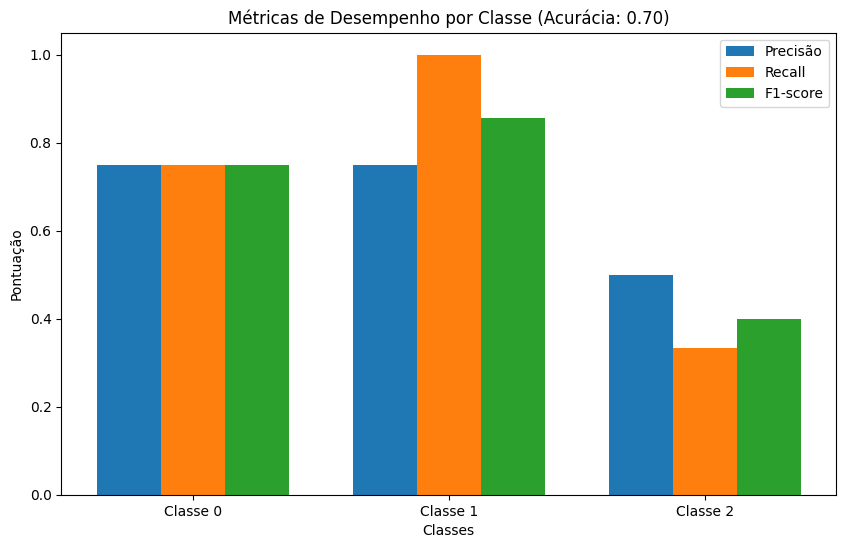

In [29]:
accuracy = accuracy_score(y_test, y_pred)
class_report = classification_report(y_test, y_pred, output_dict=True)

classes = ['Classe 0', 'Classe 1', 'Classe 2']
precision = [class_report[str(i)]['precision'] for i in range(3)]
recall = [class_report[str(i)]['recall'] for i in range(3)]
f1_score = [class_report[str(i)]['f1-score'] for i in range(3)]

fig, ax = plt.subplots(figsize=(10, 6))

bar_width = 0.25
index = np.arange(len(classes))

ax.bar(index, precision, bar_width, label='Precisão')
ax.bar(index + bar_width, recall, bar_width, label='Recall')
ax.bar(index + 2 * bar_width, f1_score, bar_width, label='F1-score')

ax.set_title(f'Métricas de Desempenho por Classe (Acurácia: {accuracy:.2f})')
ax.set_xlabel('Classes')
ax.set_ylabel('Pontuação')
ax.set_xticks(index + bar_width)
ax.set_xticklabels(classes)
ax.legend()

plt.show()